# Bounds on Two-Line IBNR Exceedance

In [1]:
from itertools import permutations

import numpy as np
import pandas as pd

import chainladder as cl

The {doc}`Value at Risk <plot_value_at_risk>` example bootstraps one
triangle and reads percentiles off the simulated IBNR. With two lines of
business, each line gets its own bootstrap distribution, and the chance
that their combined IBNR exceeds a threshold depends on how the two lines
move together. The bootstrap draws say nothing about that.

In practice an actuary picks a correlation between the lines, often from
industry studies, and the simulation pairs the draws to match it. The
Iman-Conover method does this by reordering each line's draws
{cite}`iman1982`. This example first asks how low and how high the
exceedance probability can go under any dependence at all, with both
distributions held fixed. It then checks where assumed correlations fall
between those bounds. The bounds measure how far the correlation choice
can move the answer.

`sim_ibnr` bootstraps one line of business from `clrd` and returns its
1,000 simulated totals of IBNR. Commercial auto and other liability get
separate seeds, so the two sets of draws are independent of each other.

In [2]:
clrd = cl.load_sample("clrd").groupby("LOB").sum()["CumPaidLoss"]


def sim_ibnr(lob, seed):
    sims = cl.BootstrapODPSample(random_state=seed).fit_transform(clrd.loc[lob])
    return cl.Chainladder().fit(sims).ibnr_.sum("origin").values.ravel()


x = np.sort(sim_ibnr("comauto", 42))
y = np.sort(sim_ibnr("othliab", 43))
pd.DataFrame({"comauto": x, "othliab": y}).describe(
    percentiles=[0.25, 0.5, 0.95]
).T.round(0)

,count,mean,std,min,25%,50%,95%,max
comauto,1000.0,1743843.0,65266.0,1533244.0,1701730.0,1743540.0,1852746.0,1980929.0
othliab,1000.0,1641021.0,102287.0,1322845.0,1571626.0,1635484.0,1818082.0,2012722.0


Commercial auto has a mean total IBNR of 1,743,843 and a standard deviation of 65,266. Other liability has a mean of 1,641,021 and a standard deviation of 102,287.

## Bounds over every pairing

With two samples of equal size, a dependence between the lines is a way
of pairing the draws. Each pairing gives an exceedance probability, the
share of pairs whose sum is above the threshold `b`. Every coupling of
two equally weighted samples is a mixture of one-to-one pairings by
Birkhoff's theorem, so the best and worst pairings also bound every
coupling. These are the empirical versions of the bounds in
{cite:t}`makarov1982`, and {cite:t}`embrechts2013` give the
risk-aggregation setting.

A greedy matching on the sorted draws finds both pairings.

- `upper` walks the draws of line 1 from the smallest up and tries each
  against the largest unused draw of line 2. A pair above `b` counts and
  uses up that draw of line 2. Otherwise no unused draw of line 2 can lift
  this draw of line 1 over `b`, so the matching skips it.
- `lower` runs the same matching from the other end. It counts the most
  pairs that can sit at or below `b`, and the lower bound is the share
  left over.

The small case below has draws 0, 60 and 100 on both lines and `b = 100`.
The cell checks both functions against all six pairings.

In [3]:
def upper(x, y, b):
    i, j, hits = 0, len(y) - 1, 0
    while i < len(x) and j >= 0:
        if x[i] + y[j] > b:
            hits += 1
            j -= 1
        i += 1
    return hits / len(x)


def lower(x, y, b):
    i, j, fits = len(x) - 1, 0, 0
    while i >= 0 and j < len(y):
        if x[i] + y[j] <= b:
            fits += 1
            j += 1
        i -= 1
    return 1 - fits / len(x)


def independent(x, y, b):
    return np.mean(np.add.outer(x, y) > b)


toy = np.array([0, 60, 100])
pairings = [np.mean(toy + toy[list(p)] > 100) for p in permutations(range(3))]
pd.Series({
    "lower": lower(toy, toy, 100),
    "smallest of six pairings": min(pairings),
    "independent": independent(toy, toy, 100),
    "upper": upper(toy, toy, 100),
    "largest of six pairings": max(pairings),
}).round(3)

lower                       0.333
smallest of six pairings    0.333
independent                 0.444
upper                       0.667
largest of six pairings     0.667
dtype: float64

The six pairings range from 1/3 to 2/3, and both functions find those two ends. Independence gives 4/9.

The table below applies the bounds to the bootstrap draws. Each
threshold adds the same percentile of the two lines.

In [4]:
rows = []
for q in (0.25, 0.5, 0.75, 0.95, 0.99):
    b = np.quantile(x, q) + np.quantile(y, q)
    rows.append({
        "percentile": q,
        "threshold b": b,
        "lower": lower(x, y, b),
        "independent": independent(x, y, b),
        "upper": upper(x, y, b),
    })
bounds = pd.DataFrame(rows).set_index("percentile")
bounds.round({"threshold b": 0, "lower": 3, "independent": 3, "upper": 3})

,threshold b,lower,independent,upper
percentile,,,,
0.25,3273356.0,0.514,0.825,1.000
0.50,3379024.0,0.104,0.506,0.906
0.75,3488936.0,0.012,0.186,0.481
0.95,3670828.0,0.000,0.016,0.091
0.99,3823097.0,0.000,0.000,0.018


At the sum of the 25th percentiles, 3,273,356, the exceedance probability runs from 0.514 to 1.000, with 0.825 under independence. At the sum of the 95th percentiles, 3,670,828, it runs from 0.000 to 0.091, with 0.016 under independence. The range is widest at the median, from 0.104 to 0.906. A floor of zero at the high thresholds is correct, because pairing opposite ranks keeps every sum at or below `b`.

## Assumed correlations fall inside the bounds

`reorder` pairs the draws the way a correlation assumption would. It
draws 1,000 pairs of standard normals with correlation `rho`, then
reorders each line's sorted draws by the ranks of its normals. This is a
simple version of the Iman-Conover idea. Each `rho` is averaged over 200
reorderings.

In [5]:
def reorder(rho, rng):
    z1 = rng.standard_normal(len(x))
    z2 = rho * z1 + np.sqrt(1 - rho**2) * rng.standard_normal(len(x))
    return x[np.argsort(np.argsort(z1))], y[np.argsort(np.argsort(z2))]


rhos = [-1.0, -0.5, 0.0, 0.25, 0.5, 0.75, 1.0]
b95 = bounds.loc[0.95, "threshold b"]
rng = np.random.default_rng(0)
sweep = pd.Series(
    {
        rho: np.mean([np.mean(np.add(*reorder(rho, rng)) > b95) for _ in range(200)])
        for rho in rhos
    },
    name="exceedance at the 95th percentile threshold",
)
sweep.index.name = "rho"
sweep.round(3)

rho
-1.00    0.000
-0.50    0.002
 0.00    0.016
 0.25    0.025
 0.50    0.034
 0.75    0.042
 1.00    0.050
Name: exceedance at the 95th percentile threshold, dtype: float64

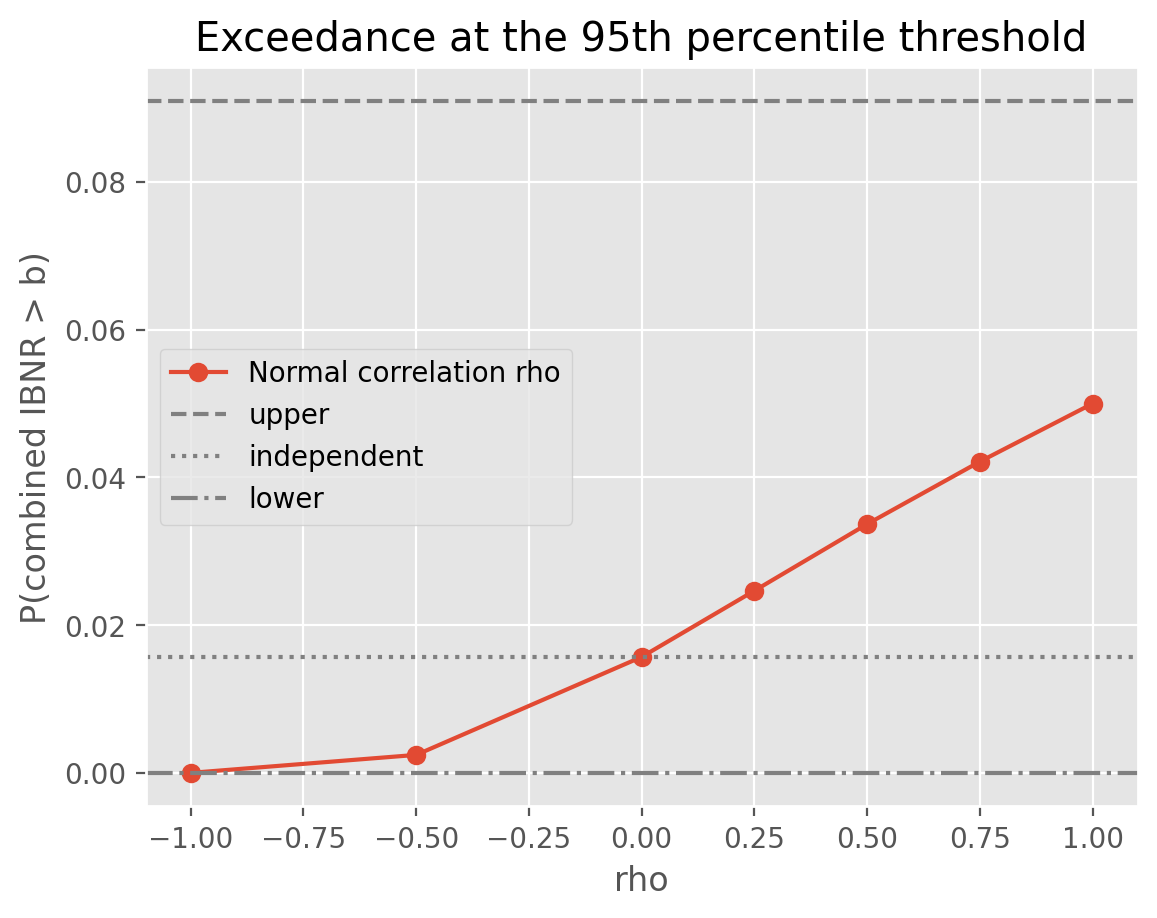

In [6]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")
%config InlineBackend.figure_format = 'retina'

fig, ax = plt.subplots()
ax.plot(sweep.index, sweep.values, marker="o", label="Normal correlation rho")
for name, style in (("upper", "--"), ("independent", ":"), ("lower", "-.")):
    ax.axhline(bounds.loc[0.95, name], color="grey", linestyle=style, label=name)
ax.set_xlabel("rho")
ax.set_ylabel("P(combined IBNR > b)")
ax.set_title("Exceedance at the 95th percentile threshold")
ax.legend();

The exceedance probability rises with `rho`, from 0.000 at -1 through 0.016 at 0 to 0.050 at 1. Every value sits between the bounds, as it must, since each reordering is one of the pairings the bounds cover. Perfect correlation stops well short of the upper bound of 0.091. Some pairing puts 9.1% of combined outcomes above `b`, nearly twice the 5.0% that perfect correlation gives. {cite:t}`embrechts2013` make the same point for value at risk, where the worst case for a sum is not the perfectly correlated one. A correlation assumption covers part of the range, and the bounds show how much of the range it leaves out.

## The pairing that attains the upper bound

`upper_pairs` repeats the greedy matching and keeps the pairs. The plot
compares it with the comonotone pairing, which matches ranks and is the
limit of `rho = 1`. Points above the dashed line exceed `b`.

In [7]:
def upper_pairs(x, y, b):
    i, j, pairs, left = 0, len(y) - 1, [], []
    while i < len(x) and j >= 0:
        if x[i] + y[j] > b:
            pairs.append((x[i], y[j]))
            j -= 1
        else:
            left.append(x[i])
        i += 1
    left += list(x[i:])
    pairs += zip(left, y[: len(left)][::-1])
    return np.array(pairs)


worst = upper_pairs(x, y, b95)
pd.Series({
    "pairs": len(worst),
    "share above b, greedy pairing": np.mean(worst.sum(axis=1) > b95),
    "share above b, comonotone pairing": np.mean(x + y > b95),
}).round(3)

pairs                                1000.000
share above b, greedy pairing           0.091
share above b, comonotone pairing       0.050
dtype: float64

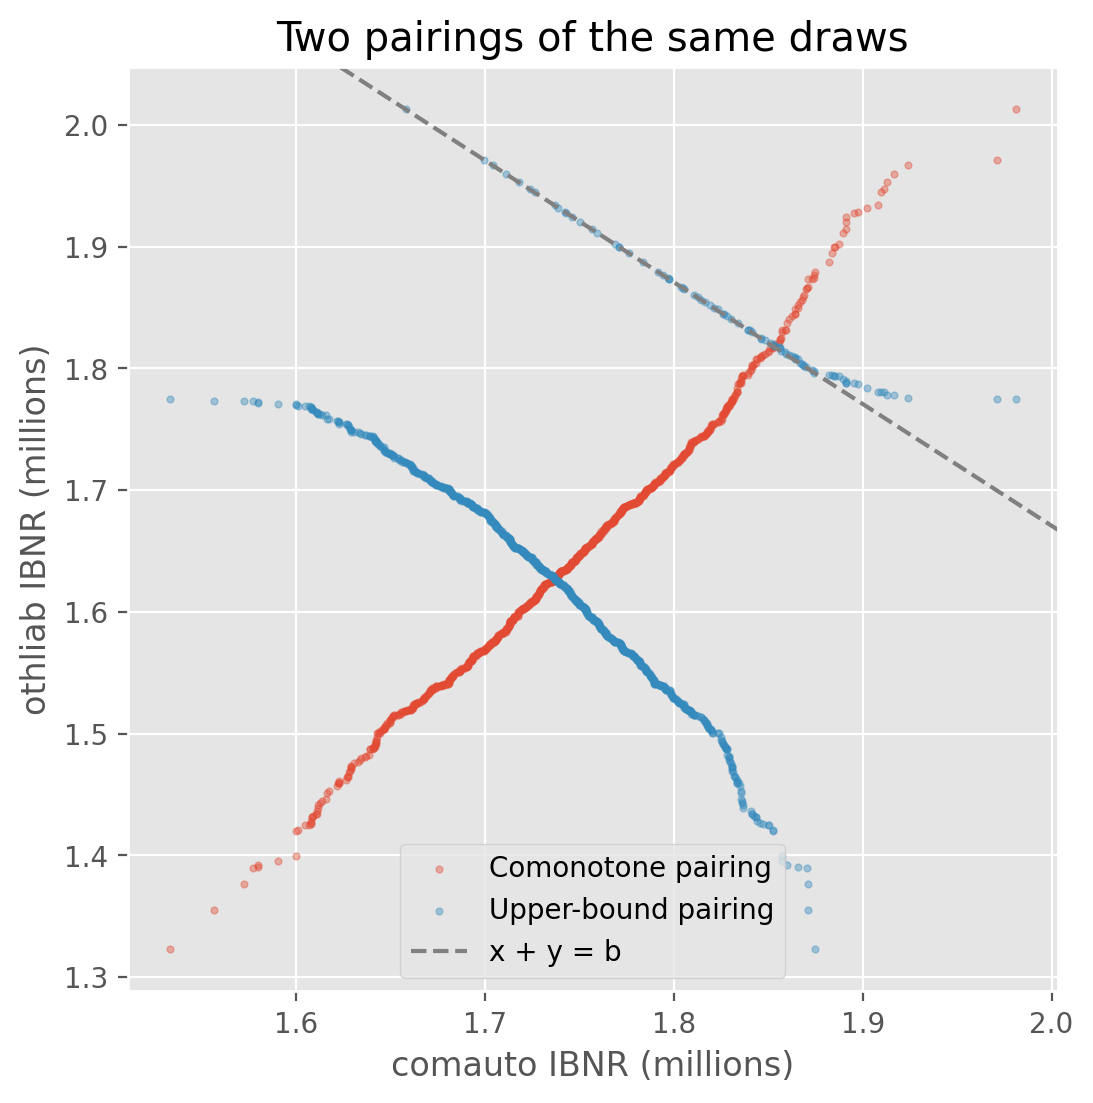

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x / 1e6, y / 1e6, s=6, alpha=0.4, label="Comonotone pairing")
ax.scatter(
    worst[:, 0] / 1e6, worst[:, 1] / 1e6, s=6, alpha=0.4, label="Upper-bound pairing"
)
limits = ax.get_xlim(), ax.get_ylim()
ax.axline((b95 / 1e6, 0), slope=-1, color="grey", linestyle="--", label="x + y = b")
ax.set(xlim=limits[0], ylim=limits[1])
ax.set_xlabel("comauto IBNR (millions)")
ax.set_ylabel("othliab IBNR (millions)")
ax.set_title("Two pairings of the same draws")
ax.legend();

The greedy pairing puts 91 of the 1,000 pairs above `b`, where the comonotone pairing puts 50. The comonotone points form a rising curve that crosses the line only at its top end. The greedy pairing gives each of the largest draws of other liability the smallest draw of commercial auto that still clears `b`, so most of its pairs above `b` sit just above the line. Its other pairs form a falling band well below the line.